In [2]:
import numpy as np
import pandas as pd
import pyagrum as gum
import pyagrum.lib.notebook as gnb
import pyagrum.lib.dynamicBN as gdyn

from cross_impact.model import build_network, UncertaintyFactor, CrossImpactNetwork
from cross_impact.pyagrum_import import marginals_and_joint_from_pyagrum
from cross_impact.pyagrum_export import graft_onto_pyagrum
from cross_impact.model import cross_impacts_from_joint

In [3]:
# The uncertainty factors, or dnb nodes
factortuples = [
    ("HHA0", 3, ()),
    ("GER0", 2, ()),
    ("OMA0", 2, ()),
    ("PIS0", 5, ()),
    ("PIH0", 5, (0,3,)),
    ("LYS0", 4, (3,4,)),
    ("LYH0", 7, (0,2,3,4,5,)),
    ("AST0", 3, (1,2,4,6,)),
     
    ("HHAt", 3, ()),
    ("GERt", 2, ()),
    ("OMAt", 2, ()),
    ("PISt", 5, (4,5,6,)),
    ("PIHt", 5, (1,2,6,8,11,)),
    ("LYSt", 4, (1,2,6,11,12,)),
    ("LYHt", 7, (1,2,6,8,10,11,12,13,)),
    ("ASTt", 3, (9, 10, 12, 14)),
]
factors = [UncertaintyFactor(factor[0], factor[1], factor[2]) for factor in factortuples]

In [4]:
# marginals for each uncertainty factor
hha_mar = np.array([0.3, 0.4, 0.3])
ger_mar = np.array([0.7, 0.3])
oma_mar = np.array([0.5, 0.5])
pis_mar = np.array([0.0993, 0.388, 0.4343, 0.0784, 0])
pih_mar = np.array([0.7467, 0.042, 0.14, 0.0663, 0.005])
lys_mar = np.array([0.9637, 0.0099, 0.0185, 0.0079])
lyh_mar = np.array([0.950, 0.031, 0.005, 0.01, 0.001, 0.003, 0])
ast_mar = np.array([0.5, 0.2, 0.3])

In [5]:
cross_impacts = {}
for fi, factor in enumerate(factortuples):
    for parent_index in factor[2]:
        factor_dim = factor[1]
        parent_dim = factortuples[parent_index][1]
        cross_impacts[(parent_index, fi)] = np.ones((parent_dim, factor_dim))

In [6]:
network = CrossImpactNetwork(
    factors=factors,
    marginals=[
        hha_mar,
        ger_mar,
        oma_mar,
        pis_mar,
        pih_mar,
        lys_mar,
        lyh_mar,
        ast_mar,
        hha_mar,
        ger_mar,
        oma_mar,
        pis_mar,
        pih_mar,
        lys_mar,
        lyh_mar,
        ast_mar,
    ],
    cross_impacts=cross_impacts,
)
built = build_network(network, mode="independent", initial_joint=None)

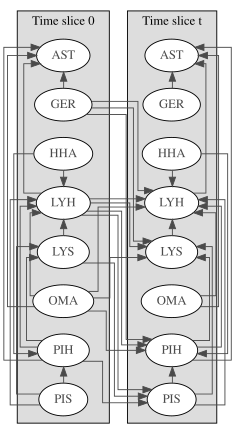

In [7]:
from cross_impact.pyagrum_export import to_pyagrum

bn = to_pyagrum(built)
gdyn.showTimeSlices(bn)

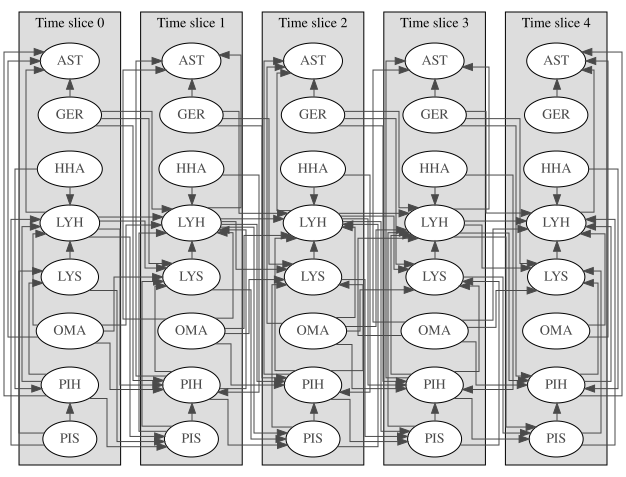

In [8]:
T = 5
dbn = gdyn.unroll2TBN(bn, T)
gdyn.showTimeSlices(dbn, size="10")

In [9]:
dbn.cpt("LYS4")

(pyagrum.Tensor@0x162fe430) 
                                  ||  LYS4                                 |
GER3  |OMA3  |LYH3  |PIS4  |PIH4  ||0        |1        |2        |3        |
------|------|------|------|------||---------|---------|---------|---------|
0     |0     |0     |0     |0     || 0.9583  | 0.0124  | 0.0197  | 0.0097  |
1     |0     |0     |0     |0     || 0.9762  | 0.0071  | 0.0112  | 0.0056  |
0     |1     |0     |0     |0     || 0.9583  | 0.0124  | 0.0197  | 0.0097  |
1     |1     |0     |0     |0     || 0.9762  | 0.0071  | 0.0112  | 0.0056  |
0     |0     |1     |0     |0     || 0.9928  | 0.0019  | 0.0037  | 0.0016  |
1     |0     |1     |0     |0     || 0.9969  | 0.0008  | 0.0016  | 0.0007  |
[...688 more line(s) ...]
0     |1     |5     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
1     |1     |5     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
0     |0     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
1     |0     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
0     |1     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |
1     |1     |6     |4     |4     || 0.2500  | 0.2500  | 0.2500  | 0.2500  |